<a href="https://colab.research.google.com/github/clobos/ECO5056_2026/blob/main/Redes_Neurais_Profundas_ECO5056.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# CONCEITOS TEÓRICOS


1. Hiperparâmetros:
   - Taxa de Aprendizado (Learning Rate - lr): Controla o tamanho do passo que o otimizador dá na direção oposta ao gradiente em cada iteração. Valores muito altos podem causar divergência; valores muito baixos tornam o treinamento lento e suscetível a mínimos locais.
   - Dropout: Técnica de regularização que desativa aleatoriamente uma fração (ex: 20%) de neurônios a cada etapa de treino, forçando a rede a aprender representações robustas e distribuídas, mitigando o sobreajuste (overfitting).
   - Tamanho do Lote (Batch Size): O número de amostras processadas antes de atualizar os pesos internos do modelo. Lotes menores inserem ruído estocástico no gradiente (o que pode ajudar a escapar de mínimos locais), enquanto lotes maiores dão estimativas de gradiente mais estáveis.

2. Funções de Ativação:
   - ReLU (Rectified Linear Unit): f(z) = max(0, z). Introduz não-linearidade no modelo sem sofrer com o desvanecimento de gradiente para valores positivos, o que acelera drasticamente a convergência.
   - Sigmoide: f(z) = 1 / (1 + e^-z). Espreme as ativações no intervalo [0, 1]. Essencial para classificação binária na camada de saída, representando a probabilidade da classe positiva.
   - Linear: f(z) = z. Usada na camada de saída de regressões, permitindo que a rede projete qualquer valor real contínuo sem restrições.

3. Processo de Estimação (Otimização):
   - O treinamento utiliza o algoritmo Backpropagation (retropropagação de erros) combinado com o otimizador Adam (Adaptive Moment Estimation). Os gradientes da função de perda (MSE para regressão ou Binary Crossentropy para classificação) em relação aos pesos são calculados da última camada para a primeira utilizando a regra da cadeia de derivadas. Os pesos são então atualizados de forma adaptativa com base nos momentos de primeira e segunda ordem dos gradientes.



## Gráfico: funções de ativação  

In [28]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2" # esconde mensagens internas e verbosas do TensorFlow
import numpy as np     # álgebra linear e vetores/matrizes
import matplotlib      # biblioteca de gráficos
matplotlib.use("Agg")  # usa backend sem janela: salva figuras em arquivo
import matplotlib.pyplot as plt  # interface de desenho do matplotlib
import tensorflow as tf  # motor de cálculo (diferenciação automática, GPU/CPU)
from tensorflow import keras           # API de alto nível para construir redes
from tensorflow.keras import layers    # camadas densas, dropout etc.
from sklearn.datasets import load_diabetes, load_breast_cancer   # dois conjuntos de dados reais
from sklearn.model_selection import train_test_split # separa treino e teste
from sklearn.preprocessing import StandardScaler # padronização (média 0, desvio 1)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, roc_curve, roc_auc_score, accuracy_score)

keras.utils.set_random_seed(42)    # fixa sementes: resultados reproduzíveis



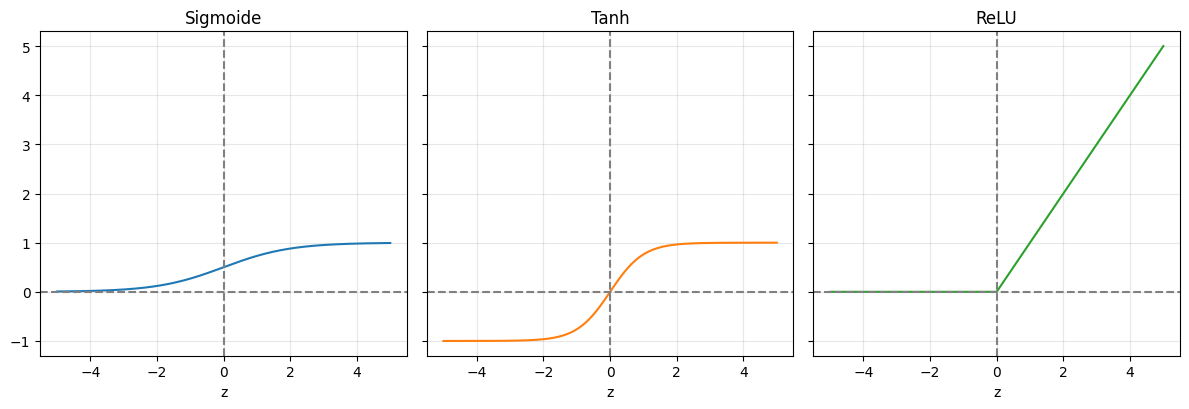

In [29]:

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-5, 5, 400)                           # 400 pontos entre -5 e 5
sigm = 1 / (1 + np.exp(-z))                           # sigmoide

# Criando figura com 1 linha e 3 colunas compartilhando o mesmo eixo y
fig1, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)

# Subplot 1: Sigmoide
axs[0].plot(z, sigm, label="sigmoide", color="C0")
axs[0].axhline(0, color="gray", linestyle="--")
axs[0].axvline(0, color="gray", linestyle="--")
axs[0].set_title("Sigmoide")
axs[0].set_xlabel("z")
axs[0].grid(alpha=0.3)

# Subplot 2: Tanh
axs[1].plot(z, np.tanh(z), label="tanh", color="C1")
axs[1].axhline(0, color="gray", linestyle="--")
axs[1].axvline(0, color="gray", linestyle="--")
axs[1].set_title("Tanh")
axs[1].set_xlabel("z")
axs[1].grid(alpha=0.3)

# Subplot 3: ReLU
axs[2].plot(z, np.maximum(0, z), label="ReLU", color="C2")
axs[2].axhline(0, color="gray", linestyle="--")
axs[2].axvline(0, color="gray", linestyle="--")
axs[2].set_title("ReLU")
axs[2].set_xlabel("z")
axs[2].grid(alpha=0.3)

fig1.tight_layout()
plt.show()

## Gráfico : derivadas das funções de ativação

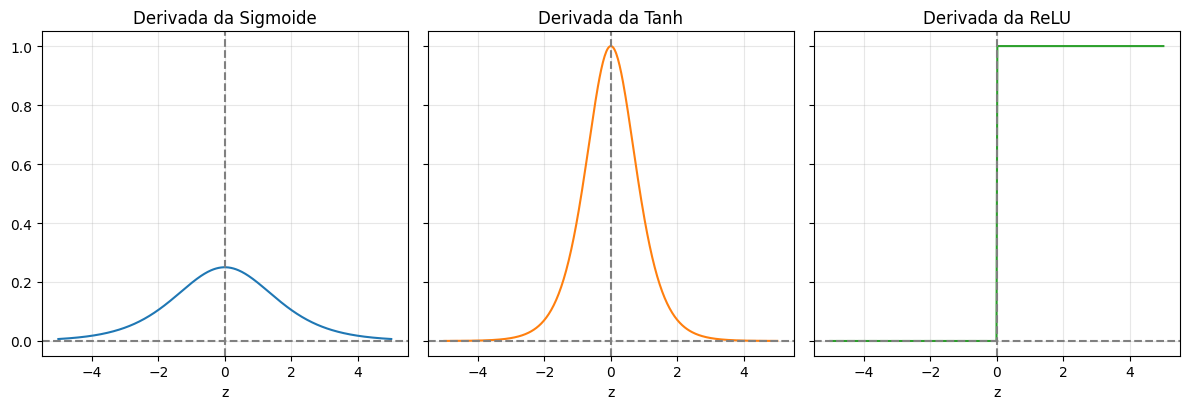

In [30]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-5, 5, 400)
sigm = 1 / (1 + np.exp(-z))

# Criando figura com 1 linha e 3 colunas compartilhando o mesmo eixo y
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)

# Subplot 1: Derivada da Sigmoide
deriv_sigm = sigm * (1 - sigm)
axs2[0].plot(z, deriv_sigm, label="d_sigmoide", color="C0")
axs2[0].axhline(0, color="gray", linestyle="--")
axs2[0].axvline(0, color="gray", linestyle="--")
axs2[0].set_title("Derivada da Sigmoide")
axs2[0].set_xlabel("z")
axs2[0].grid(alpha=0.3)

# Subplot 2: Derivada da Tanh
deriv_tanh = 1 - np.tanh(z)**2
axs2[1].plot(z, deriv_tanh, label="d_tanh", color="C1")
axs2[1].axhline(0, color="gray", linestyle="--")
axs2[1].axvline(0, color="gray", linestyle="--")
axs2[1].set_title("Derivada da Tanh")
axs2[1].set_xlabel("z")
axs2[1].grid(alpha=0.3)

# Subplot 3: Derivada da ReLU
deriv_relu = np.where(z > 0, 1, 0)
axs2[2].plot(z, deriv_relu, label="d_ReLU", color="C2")
axs2[2].axhline(0, color="gray", linestyle="--")
axs2[2].axvline(0, color="gray", linestyle="--")
axs2[2].set_title("Derivada da ReLU")
axs2[2].set_xlabel("z")
axs2[2].grid(alpha=0.3)

fig2.tight_layout()
plt.show()

## FUNÇÃO PARA CONSTRUIR A REDE MLP

In [31]:
def build_mlp(n_features, task, lr=1e-3, dropout=0.2, hidden=(64, 32)):
    # n_features: número de entradas (colunas de X)
    # task: "regression" ou "classification"
    # lr: taxa de aprendizado do otimizador Adam
    # dropout: fração de neurônios desligados em cada passo de treino
    # hidden: tupla com o número de neurônios de cada camada oculta
    model = keras.Sequential(name=f"mlp_{task}")   # rede sequencial: camada após camada
    model.add(layers.Input(shape=(n_features,)))   # declara o formato da entrada (sem camada de cálculo)
    for units in hidden:                           # para cada camada oculta...
        model.add(layers.Dense(units,              # ...camada totalmente conectada com 'units' neurônios
                               activation="relu",  # função de ativação ReLU: max(0, z)
                               kernel_initializer="he_normal"))  # inicialização de pesos recomendada para ReLU
        if dropout > 0:                            # se houver dropout...
            model.add(layers.Dropout(dropout))     # ...zera uma fração aleatória de ativações (só no treino)
    if task == "regression":        # saída para regressão
        model.add(layers.Dense(1, activation="linear"))          # 1 neurônio, sem função de ativação (valor real)
        loss = "mse"                  # função de perda: erro quadrático médio
        metrics = ["mae"]             # métrica extra: erro absoluto médio
    else:                        # saída para classificação binária
        model.add(layers.Dense(1, activation="sigmoid"))         # sigmoide: converte em probabilidade entre 0 e 1
        loss = "binary_crossentropy" # função de perda: entropia cruzada binária
        metrics = ["accuracy", keras.metrics.AUC(name="auc")]    # acurácia e área sob a curva ROC
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),  # otimizador Adam com taxa lr
                  loss=loss,              # perda que será minimizada
                  metrics=metrics)        # métricas apenas para acompanhar
    return model                          # devolve a rede pronta para treinar




# REGRESSÃO (diabetes)

In [32]:
data = load_diabetes()        # carrega o conjunto de dados
X, y = data.data, data.target # X: matriz (442 x 10); y: progressão da doença (número real)
print("Formato de X:", X.shape, "| formato de y:", y.shape)

# Separação treino (80%) e teste (20%). O TESTE NÃO É USADO PARA AJUSTAR NADA.
X_trv, X_te, y_trv, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Padronização: o escalonamento é ajustado SOMENTE no treino (evita vazamento de informação).
x_scaler = StandardScaler().fit(X_trv)  # aprende média e desvio-padrão das entradas do treino
y_scaler = StandardScaler().fit(y_trv.reshape(-1, 1))  # idem para a saída (ajuda a estabilizar o treino)
Xs_trv = x_scaler.transform(X_trv) # entradas do treino padronizadas
Xs_te = x_scaler.transform(X_te)   # entradas do teste padronizadas com a MESMA escala
ys_trv = y_scaler.transform(y_trv.reshape(-1, 1)).ravel()  # alvo do treino padronizado (vetor 1D)

reg = build_mlp(n_features=X.shape[1], task="regression",
                lr=1e-3, dropout=0.2, hidden=(64, 32))  # cria a rede: 10 -> 64 -> 32 -> 1
reg.summary()               # imprime a arquitetura e o número de parâmetros



Formato de X: (442, 10) | formato de y: (442,)


Model: "mlp_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_135 (Dense)               │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_136 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_137 (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

Épocas executadas: 86 | melhor época: 61
TESTE -> RMSE: 54.13 | MAE: 44.41 | R²: 0.447


In [ ]:
# Parada antecipada: monitora a perda de validação e para quando ela deixa de melhorar.
early_reg = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # quantidade observada: perda no conjunto de validação
    patience=25,         # tolera 25 épocas sem melhora antes de parar
    restore_best_weights=True)  # ao parar, devolve os pesos da melhor época

hist_reg = reg.fit(Xs_trv, ys_trv, # treina com as entradas e o alvo padronizados
                   validation_split=0.2, # reserva 20% do treino para validação
                   epochs=500,   # no máximo 500 passagens completas pelos dados
                   batch_size=32,# tamanho do lote: 32 exemplos por atualização de pesos
                   callbacks=[early_reg], # ativa a parada antecipada
                   shuffle=True,          # embaralha os exemplos a cada época
                   verbose=0)          # não imprime o progresso de cada época
print("Épocas executadas:", len(hist_reg.history["loss"]),
      "| melhor época:", int(np.argmin(hist_reg.history["val_loss"])) + 1)



In [44]:
# Predição no teste e volta à escala original (inverse_transform desfaz a padronização)
pred_te_s = reg.predict(Xs_te, verbose=0)  # saída da rede na escala padronizada
pred_te = y_scaler.inverse_transform(pred_te_s).ravel()  # converte para a escala original do alvo

rmse = np.sqrt(mean_squared_error(y_te, pred_te))  # raiz do erro quadrático médio
mae = mean_absolute_error(y_te, pred_te)   # erro absoluto médio
r2 = r2_score(y_te, pred_te)               # proporção da variância explicada
print(f"TESTE -> RMSE: {rmse:.2f} | MAE: {mae:.2f} | R²: {r2:.3f}")

TESTE -> RMSE: 54.13 | MAE: 44.41 | R²: 0.447


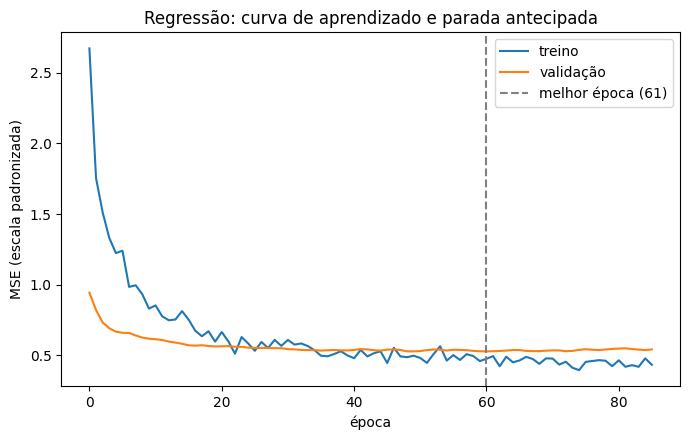

In [33]:
# Força o matplotlib a renderizar os gráficos diretamente no notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# --- Gráfico 1: curvas de perda (treino x validação) com a época ótima marcada ---
fig, ax = plt.subplots(figsize=(7, 4.5))           # Cria uma figura e eixo individual
ax.plot(hist_reg.history["loss"], label="treino")  # perda de treino a cada época
ax.plot(hist_reg.history["val_loss"], label="validação")  # perda de validação a cada época
best = int(np.argmin(hist_reg.history["val_loss"]))
ax.axvline(best, ls="--", c="gray", label=f"melhor época ({best+1})")  # linha vertical
ax.set_xlabel("época"); ax.set_ylabel("MSE (escala padronizada)")
ax.set_title("Regressão: curva de aprendizado e parada antecipada")
ax.legend()
fig.tight_layout()
plt.show()                                         # mostra o primeiro gráfico




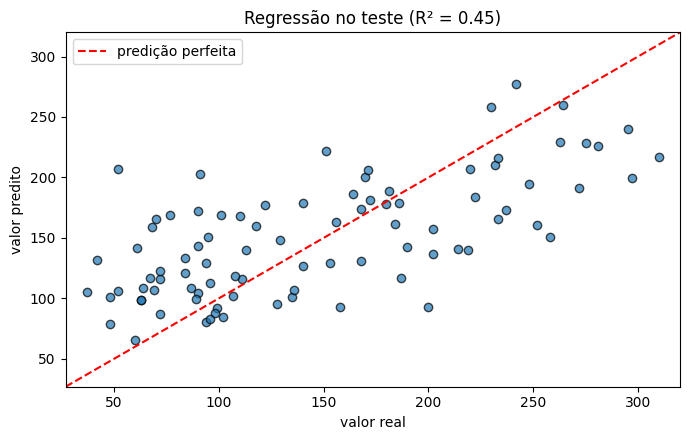

In [34]:
# --- Gráfico 2: real x predito no teste ---
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(y_te, pred_te, alpha=0.7, edgecolor="k")  # cada ponto é um paciente do teste
lims = [min(y_te.min(), pred_te.min()) - 10, max(y_te.max(), pred_te.max()) + 10]
ax.plot(lims, lims, "r--", label="predição perfeita")  # linha y = x
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("valor real"); ax.set_ylabel("valor predito")
ax.set_title(f"Regressão no teste (R² = {r2:.2f})"); ax.legend()
fig.tight_layout()
plt.show()           # mostra o segundo gráfico

In [35]:
# Definição do espaço de busca para regressão
grid_reg = [
    {"lr": lr, "dropout": d, "batch": b}
    for lr in [1e-2, 1e-3]
    for d in [0.0, 0.2]
    for b in [16, 32]
]

resultados_reg = []

print("Iniciando Grid Search para Regressão...")
for g in grid_reg:
    keras.utils.set_random_seed(42)  # Garantir reprodutibilidade

    # Criação da MLP com a tarefa de regressão ('regression')
    m = build_mlp(
        n_features=X.shape[1],
        task="regression",
        lr=g["lr"],
        dropout=g["dropout"],
        hidden=(64, 32)
    )

    # Ajuste (treinamento) com dados de validação cruzada implícita (20% split)
    h = m.fit(
        Xs_trv, ys_trv,
        validation_split=0.2,
        epochs=200,
        batch_size=g["batch"],
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)],
        verbose=0
    )

    melhor_val = float(np.min(h.history["val_loss"]))
    melhor_ep = int(np.argmin(h.history["val_loss"])) + 1
    resultados_reg.append((g, melhor_val, melhor_ep, h.history))

    print(f"lr={g['lr']:<6} dropout={g['dropout']:<4} batch={g['batch']:<3} "
          f"-> val_loss (MSE)={melhor_val:.4f} (época {melhor_ep})")



Iniciando Grid Search para Regressão...
lr=0.01   dropout=0.0  batch=16  -> val_loss (MSE)=0.4998 (época 6)
lr=0.01   dropout=0.0  batch=32  -> val_loss (MSE)=0.5089 (época 10)
lr=0.01   dropout=0.2  batch=16  -> val_loss (MSE)=0.4828 (época 5)
lr=0.01   dropout=0.2  batch=32  -> val_loss (MSE)=0.4889 (época 16)
lr=0.001  dropout=0.0  batch=16  -> val_loss (MSE)=0.6076 (época 21)
lr=0.001  dropout=0.0  batch=32  -> val_loss (MSE)=0.6035 (época 37)
lr=0.001  dropout=0.2  batch=16  -> val_loss (MSE)=0.5358 (época 31)
lr=0.001  dropout=0.2  batch=32  -> val_loss (MSE)=0.5282 (época 61)


## MODELO FINAL COM OS MELHORES HIPERPARÂMETROS

In [36]:
# Seleção do melhor conjunto de hiperparâmetros com base no menor MSE de validação
melhor_hp_reg = min(resultados_reg, key=lambda r: r[1])[0]
print("\nMelhores Hiperparâmetros para Regressão:", melhor_hp_reg)

keras.utils.set_random_seed(42)
reg_final = build_mlp(
    n_features=X.shape[1],
    task="regression",
    lr=melhor_hp_reg["lr"],
    dropout=melhor_hp_reg["dropout"],
    hidden=(64, 32)
)

hist_reg_final = reg_final.fit(
    Xs_trv, ys_trv,
    validation_split=0.2,
    epochs=300,
    batch_size=melhor_hp_reg["batch"],
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)],
    verbose=0
)




Melhores Hiperparâmetros para Regressão: {'lr': 0.01, 'dropout': 0.2, 'batch': 16}


## Avaliação final no conjunto de testes




In [37]:
pred_te_s = reg_final.predict(Xs_te, verbose=0)
pred_te = y_scaler.inverse_transform(pred_te_s).ravel()

rmse_f = np.sqrt(mean_squared_error(y_te, pred_te))
mae_f = mean_absolute_error(y_te, pred_te)
r2_f = r2_score(y_te, pred_te)

print(f"\nRESULTADOS FINAIS (TESTE) COM MELHORES HP -> RMSE: {rmse_f:.2f} | MAE: {mae_f:.2f} | R²: {r2_f:.3f}")


RESULTADOS FINAIS (TESTE) COM MELHORES HP -> RMSE: 52.31 | MAE: 43.04 | R²: 0.484


# CLASSIFICAÇÃO BINÁRIA (câncer de mama: maligno = 0, benigno = 1)

In [38]:
cancer = load_breast_cancer()                      # carrega o conjunto de dados
Xc, yc = cancer.data, cancer.target                # Xc: 569 x 30; yc: rótulos 0 ou 1
print("Formato de Xc:", Xc.shape, "| classes:", dict(zip(cancer.target_names, np.bincount(yc))))

# stratify=yc mantém a proporção das classes igual no treino e no teste
Xc_trv, Xc_te, yc_trv, yc_te = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)
sc = StandardScaler().fit(Xc_trv)   # padronizador ajustado só no treino
Xc_trv_s = sc.transform(Xc_trv)     # treino padronizado
Xc_te_s = sc.transform(Xc_te)       # teste padronizado com a mesma escala



Formato de Xc: (569, 30) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


## BUSCA DE HIPERPARÂMETROS (grade simples)

In [39]:
grid = [{"lr": lr, "dropout": d, "batch": b} # cada dicionário é uma combinação
        for lr in [1e-2, 1e-3]               # taxa de aprendizado
        for d in [0.0, 0.3]                  # taxa de dropout
        for b in [16, 64]]                   # tamanho do lote
resultados = []                         # guarda o resultado de cada combinação
for g in grid:
    keras.utils.set_random_seed(42)     # mesma semente para comparação justa
    m = build_mlp(Xc.shape[1], "classification", lr=g["lr"], dropout=g["dropout"], hidden=(32, 16))
    h = m.fit(Xc_trv_s, yc_trv,               # treina com o treino padronizado
              validation_split=0.2, epochs=300, # 20% do treino vira validação
              batch_size=g["batch"],
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                                       restore_best_weights=True)],
              verbose=0)
    melhor_val = float(np.min(h.history["val_loss"]))
    melhor_ep = int(np.argmin(h.history["val_loss"])) + 1
    resultados.append((g, melhor_val, melhor_ep, h.history))
    print(f"lr={g['lr']:<6} dropout={g['dropout']:<4} lote={g['batch']:<3} "
          f"-> val_loss={melhor_val:.4f} (época {melhor_ep})")

melhor = min(resultados, key=lambda r: r[1])  # escolhe a combinação de menor perda de validação
hp = melhor[0]
print("\nMelhores hiperparâmetros:", hp)

lr=0.01   dropout=0.0  lote=16  -> val_loss=0.0260 (época 12)
lr=0.01   dropout=0.0  lote=64  -> val_loss=0.0124 (época 20)
lr=0.01   dropout=0.3  lote=16  -> val_loss=0.0141 (época 26)
lr=0.01   dropout=0.3  lote=64  -> val_loss=0.0135 (época 60)
lr=0.001  dropout=0.0  lote=16  -> val_loss=0.0146 (época 79)
lr=0.001  dropout=0.0  lote=64  -> val_loss=0.0149 (época 224)
lr=0.001  dropout=0.3  lote=16  -> val_loss=0.0187 (época 74)
lr=0.001  dropout=0.3  lote=64  -> val_loss=0.0256 (época 101)

Melhores hiperparâmetros: {'lr': 0.01, 'dropout': 0.0, 'batch': 64}


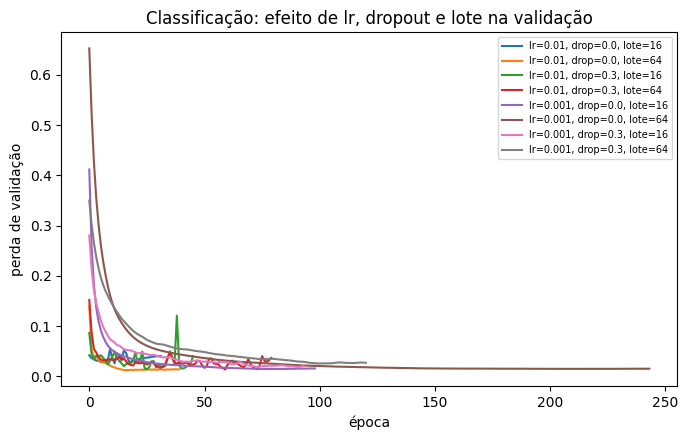

In [40]:
# Gráfico 3: curvas de validação das 8 combinações (efeito da taxa de aprendizado e do lote)
%matplotlib inline
fig, ax = plt.subplots(figsize=(7, 4.5))
for g, _, _, hist in resultados:
    ax.plot(hist["val_loss"], label=f"lr={g['lr']}, drop={g['dropout']}, lote={g['batch']}")
ax.set_xlabel("época"); ax.set_ylabel("perda de validação")
ax.set_title("Classificação: efeito de lr, dropout e lote na validação")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## TREINO FINAL com os melhores hiperparâmetros e avaliação no TESTE

In [41]:
keras.utils.set_random_seed(42)
clf = build_mlp(Xc.shape[1], "classification", lr=hp["lr"], dropout=hp["dropout"], hidden=(32, 16))
hist_clf = clf.fit(Xc_trv_s, yc_trv, validation_split=0.2, epochs=300, batch_size=hp["batch"],
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                   restore_best_weights=True)],
                   verbose=0)
prob_te = clf.predict(Xc_te_s, verbose=0).ravel()     # probabilidade de ser benigno (classe 1), entre 0 e 1
yhat_te = (prob_te >= 0.5).astype(int)                # limiar 0,5: acima vira classe 1
acc = accuracy_score(yc_te, yhat_te)                  # proporção de acertos
auc = roc_auc_score(yc_te, prob_te)                   # área sob a curva ROC (independe do limiar)
cm = confusion_matrix(yc_te, yhat_te)                 # matriz de confusão
print(f"TESTE -> acurácia: {acc:.3f} | AUC: {auc:.3f}")
print("Matriz de confusão (linhas = real, colunas = predito):\n", cm)


TESTE -> acurácia: 0.947 | AUC: 0.992
Matriz de confusão (linhas = real, colunas = predito):
 [[41  1]
 [ 5 67]]


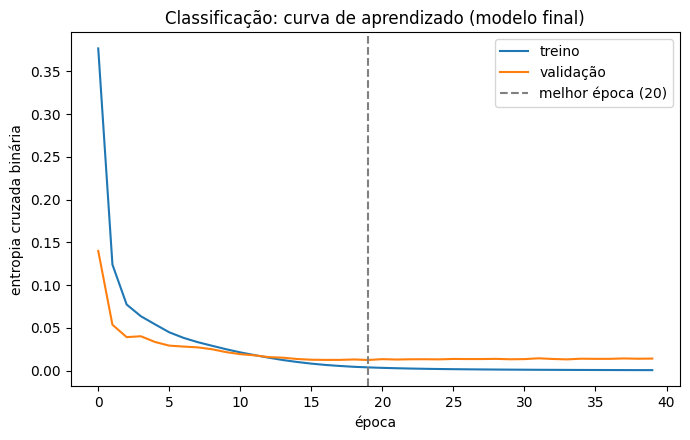

In [42]:
# Gráfico 4: curva de aprendizado do modelo final
%matplotlib inline
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(hist_clf.history["loss"], label="treino")
ax.plot(hist_clf.history["val_loss"], label="validação")
best = int(np.argmin(hist_clf.history["val_loss"]))
ax.axvline(best, ls="--", c="gray", label=f"melhor época ({best+1})")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada binária")
ax.set_title("Classificação: curva de aprendizado (modelo final)")
ax.legend()
fig.tight_layout()
plt.show()

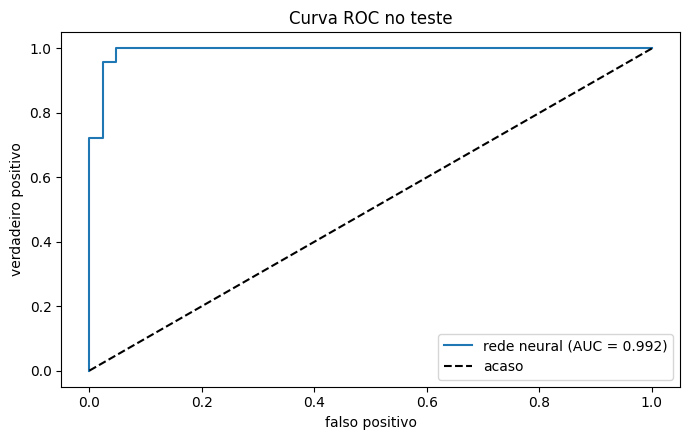

In [43]:
# Gráfico 5: curva ROC no teste
%matplotlib inline
fpr, tpr, _ = roc_curve(yc_te, prob_te)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(fpr, tpr, label=f"rede neural (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="acaso")
ax.set_xlabel("falso positivo"); ax.set_ylabel("verdadeiro positivo")
ax.set_title("Curva ROC no teste"); ax.legend()
fig.tight_layout()
plt.show()

# Codigos Simples

## Regressão

In [47]:
keras.utils.set_random_seed(42)

# 1. Construção explícita do modelo de regressão (Diabetes)
final_reg_model = keras.Sequential([
    layers.Input(shape=(Xs_trv.shape[1],)),

    # Primeira camada oculta: 64 neurônios com ativação ReLU
    layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
    layers.Dropout(0.2), # Dropout de 20% para regularização

    # Segunda camada oculta: 32 neurônios com ativação ReLU
    layers.Dense(32, activation="relu", kernel_initializer="he_normal"),
    layers.Dropout(0.2), # Dropout de 20% para regularização

    # Camada de saída: 1 neurônio com ativação Linear para regressão
    layers.Dense(1, activation="linear")
], name="final_regression_mlp")

# Compilação do modelo de regressão
final_reg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

# 2. Ajuste do modelo de regressão com dados de diabetes
history_reg_final = final_reg_model.fit(
    Xs_trv, ys_trv,
    validation_split=0.2,
    epochs=300,
    batch_size=16,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)],
    verbose=1
)

# 3. Avaliação final do modelo de regressão no teste
pred_test_scaled = final_reg_model.predict(Xs_te, verbose=0)
pred_test = y_scaler.inverse_transform(pred_test_scaled).ravel()

final_rmse = np.sqrt(mean_squared_error(y_te, pred_test))
final_mae = mean_absolute_error(y_te, pred_test)
final_r2 = r2_score(y_te, pred_test)

print(f"\n[REGRESSÃO DIABETES] Métricas de Teste:")
print(f"RMSE: {final_rmse:.2f} | MAE: {final_mae:.2f} | R²: {final_r2:.3f}")

Epoch 1/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.6309 - mae: 1.0028 - val_loss: 0.6148 - val_mae: 0.6393
Epoch 2/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6489 - mae: 0.6568 - val_loss: 0.5565 - val_mae: 0.6297
Epoch 3/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5602 - mae: 0.6174 - val_loss: 0.5278 - val_mae: 0.6072
Epoch 4/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5414 - mae: 0.5996 - val_loss: 0.5043 - val_mae: 0.5915
Epoch 5/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5268 - mae: 0.5844 - val_loss: 0.4828 - val_mae: 0.5618
Epoch 6/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5109 - mae: 0.5801 - val_loss: 0.5268 - val_mae: 0.5924
Epoch 7/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5042 - mae: 0.5796 - val_loss: 0.5578 - val_mae: 0.6072
Epoch 8/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4749 - mae: 0.5679 - val_loss: 0.5149 - val_mae: 0.5702
Epoch 9/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.52

## Classificação binária

In [48]:
keras.utils.set_random_seed(42)

# 1. Construção explícita do modelo de classificação (Câncer de Mama)
final_clf_model = keras.Sequential([
    layers.Input(shape=(Xc_trv_s.shape[1],)),

    # Primeira camada oculta: 32 neurônios com ativação ReLU
    layers.Dense(32, activation="relu", kernel_initializer="he_normal"),

    # Segunda camada oculta: 16 neurônios com ativação ReLU
    layers.Dense(16, activation="relu", kernel_initializer="he_normal"),

    # Camada de saída: 1 neurônio com ativação Sigmoide para probabilidade binária
    layers.Dense(1, activation="sigmoid")
], name="final_classification_mlp")

# Compilação do modelo de classificação
final_clf_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

# 2. Ajuste do modelo de classificação com dados de câncer de mama
history_clf_final = final_clf_model.fit(
    Xc_trv_s, yc_trv,
    validation_split=0.2,
    epochs=300,
    batch_size=64,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)],
    verbose=1
)

# 3. Avaliação final do modelo de classificação no teste
prob_test = final_clf_model.predict(Xc_te_s, verbose=0).ravel()
pred_test_classes = (prob_test >= 0.5).astype(int)

final_accuracy = accuracy_score(yc_te, pred_test_classes)
final_auc = roc_auc_score(yc_te, prob_test)
final_confusion = confusion_matrix(yc_te, pred_test_classes)

print(f"\n[CLASSIFICAÇÃO BINÁRIA CÂNCER] Métricas de Teste:")
print(f"Acurácia: {final_accuracy:.3f} | AUC: {final_auc:.3f}")
print("Matriz de Confusão:\n", final_confusion)

Epoch 1/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.8791 - auc: 0.9208 - loss: 0.3768 - val_accuracy: 0.9670 - val_auc: 0.9896 - val_loss: 0.1400
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9588 - auc: 0.9886 - loss: 0.1240 - val_accuracy: 0.9890 - val_auc: 0.9990 - val_loss: 0.0536
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9835 - auc: 0.9926 - loss: 0.0773 - val_accuracy: 0.9890 - val_auc: 1.0000 - val_loss: 0.0391
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9863 - auc: 0.9961 - loss: 0.0636 - val_accuracy: 0.9890 - val_auc: 1.0000 - val_loss: 0.0402
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9863 - auc: 0.9975 - loss: 0.0541 - val_accuracy: 0.9890 - val_auc: 1.0000 - val_loss: 0.0334
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9863 - auc: 0.9985 - loss: 0.0448 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0292
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - 

# REFERÊNCIAS PRINCIPAIS DE DEEP LEARNING EM PYTHON:

- GOODFELLOW, Ian; BENGIO, Yoshua; COURVILLE, Aaron. Deep Learning. MIT Press, 2016. (A bíblia teórica do aprendizado profundo).

- GÉRON, Aurélien. Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow. O'Reilly Media, 3ª ed., 2022. (Excelente foco prático e aplicado em Python).

- CHOLLET, François. Deep Learning with Python. Manning Publications, 2ª ed., 2021. (Escrito pelo criador do Keras, ideal para intuição prática).
"""